# 🎥 Movie Genre Time Series Forecasting (2000–2022)
**Comparative Analysis of Statistical Time Series Models (ARIMA, SARIMA, ETS)**

--- 
**Goal:** Forecast the next 12 months of monthly market share (%) across movie genres using a rigorous chronological split (Train / Validation / Test), selecting the optimal model per genre, and evaluating out-of-sample performance.

In [1]:
import json
import warnings
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.arima.model import ARIMA

warnings.simplefilter("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(19)

# Directory setup
OUT = Path("../outputs")
D = {name: OUT / name for name in ["data", "tables", "forecasts", "models", "figures"]}
for folder in D.values(): 
    folder.mkdir(parents=True, exist_ok=True)

SEASON = 12
HORIZON = 12

## 1. Load and Preprocess Data (2000–2022 Range)

In [2]:
raw = pd.read_csv("../data/processed/monthly_genre_market_share.csv")
raw["date"] = pd.to_datetime(raw["date"])

# Filter for the requested time range: 2000-01-01 to 2022-12-01
raw = raw[(raw["date"] >= "2000-01-01") & (raw["date"] <= "2022-12-01")]
df = raw.sort_values("date").set_index("date")
GENRES = list(df.columns)

# Reindex to full monthly frequency and apply linear interpolation for any gaps
full_index = pd.date_range(df.index.min(), df.index.max(), freq="MS")
df = df.reindex(full_index)
df.index.name = "date"
df = df.interpolate(method="linear")
df.index.freq = "MS"

print(f"Dataset Shape (Filtered & Interpolated): {df.shape}")
print(f"Date Range: {df.index.min().date()} to {df.index.max().date()}")
df.to_csv(D["data"] / "prepared_monthly_genre_share.csv")

Dataset Shape (Filtered & Interpolated): (276, 7)
Date Range: 2000-01-01 to 2022-12-01


## 2. Chronological Train / Validation / Test Split (70% / 15% / 15%)

In [3]:
n = len(df)
n_train = int(round(0.70 * n))
n_val = int(round(0.15 * n))

train = df.iloc[:n_train]
val = df.iloc[n_train:n_train + n_val]
test = df.iloc[n_train + n_val:]

split_table = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "start": [x.index[0].date() for x in (train, val, test)],
    "end": [x.index[-1].date() for x in (train, val, test)],
    "months": [len(train), len(val), len(test)],
    "share_of_data_%": [round(100 * len(x) / n, 1) for x in (train, val, test)]
})
display(split_table)
split_table.to_csv(D["tables"] / "split_ranges.csv", index=False)

,set,start,end,months,share_of_data_%
0,train,2000-01-01,2016-01-01,193,69.9
1,validation,2016-02-01,2019-06-01,41,14.9
2,test,2019-07-01,2022-12-01,42,15.2


## 3. Utility Functions & Seasonality Check

In [4]:
def mae(a, f): return float(np.mean(np.abs(np.asarray(a) - np.asarray(f))))
def rmse(a, f): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(f)) ** 2)))
def mape(a, f): 
    a, f = np.asarray(a, float), np.asarray(f, float)
    return float(np.mean(np.abs((a - f) / a)) * 100)
def metrics(a, f): return {"MAE": mae(a, f), "RMSE": rmse(a, f), "MAPE": mape(a, f)}

def normalize(pred):
    clipped = pred.clip(lower=0)
    totals = clipped.sum(axis=1)
    return clipped.div(totals, axis=0) * 100

def fit_model(family, cfg, y):
    if family == "ETS":
        model = ETSModel(y, error=cfg["error"], trend=cfg["trend"], damped_trend=cfg["damped"],
                         seasonal=cfg["seasonal"], seasonal_periods=SEASON if cfg["seasonal"] else None)
        return model.fit(disp=False)
    model = ARIMA(y, order=tuple(cfg["order"]), seasonal_order=tuple(cfg.get("seasonal_order", (0, 0, 0, 0))), trend=cfg["trend"])
    return model.fit()

# Check seasonal strength via STL on training data
def seasonal_strength(y):
    r = STL(y, period=SEASON, robust=True).fit()
    return max(0.0, 1 - r.resid.var() / (r.seasonal + r.resid).var())

strength = pd.Series({g: seasonal_strength(train[g]) for g in GENRES})
seasonal_need = strength >= 0.30
season_table = pd.DataFrame({"seasonal_strength": strength.round(3), "seasonal_models_used": seasonal_need})
display(season_table)

,seasonal_strength,seasonal_models_used
Action,0.229,False
Adventure,0.349,True
Comedy,0.314,True
Drama,0.222,False
Romance,0.101,False
Sci-Fi,0.244,False
Thriller,0.268,False


## 4. Model Grid Search & Validation Selection

In [5]:
def ets_grid(seasonal):
    seasons = [None, "add"] if seasonal else [None]
    trends = [(None, False), ("add", False), ("add", True)]
    return [dict(error=e, trend=t, damped=dm, seasonal=s) for e, (t, dm), s in product(["add", "mul"], trends, seasons)]

def arima_grid():
    return [dict(order=(p, d, q), trend="c" if d == 0 else "n") for p, d, q in product(range(3), (0, 1), range(3))]

ORIGINS = range(0, len(val) - HORIZON + 1, HORIZON)
log_rows = []

for g in GENRES:
    families = {"ETS": ets_grid(seasonal_need[g]), "ARIMA": arima_grid()}
    for family, cfgs in families.items():
        for cfg in cfgs:
            actual, pred = [], []
            for o in ORIGINS:
                try:
                    res = fit_model(family, cfg, df[g].iloc[: n_train + o])
                    pred += list(res.forecast(HORIZON))
                    actual += list(val[g].values[o: o + HORIZON])
                    if o == 0:
                        aic, bic = float(res.aic), float(res.bic)
                except Exception:
                    continue
            if actual:
                m = metrics(actual, pred)
                log_rows.append(dict(genre=g, family=family, cfg=cfg, val_RMSE=m["RMSE"], aic=aic, bic=bic))

grid_log = pd.DataFrame(log_rows)
best = grid_log.sort_values(["genre", "val_RMSE", "aic"]).groupby("genre", as_index=False).first()
display(best[["genre", "family", "cfg", "val_RMSE", "aic"]].round(3))

,genre,family,cfg,val_RMSE,aic
0,Action,ETS,"{'error': 'add', 'trend': 'add', 'damped': Fal...",0.334,269.597
1,Adventure,ARIMA,"{'order': (0, 1, 0), 'trend': 'n'}",0.298,209.229
2,Comedy,ARIMA,"{'order': (2, 0, 2), 'trend': 'c'}",0.572,277.635
3,Drama,ETS,"{'error': 'add', 'trend': 'add', 'damped': Fal...",0.904,408.320
4,Romance,ETS,"{'error': 'add', 'trend': 'add', 'damped': Fal...",0.222,151.734
5,Sci-Fi,ETS,"{'error': 'mul', 'trend': 'add', 'damped': Fal...",0.274,167.178
6,Thriller,ARIMA,"{'order': (2, 1, 0), 'trend': 'n'}",0.330,172.825


## 5. Test Evaluation & Future Forecasting (2023)

In [6]:
# Refit selected models on full data and forecast future horizon
future_index = pd.date_range(df.index[-1] + pd.offsets.MonthBegin(1), periods=HORIZON, freq="MS")
future_raw = pd.DataFrame(index=future_index, columns=GENRES, dtype=float)
selected_models = {}

for _, row in best.iterrows():
    g = row["genre"]
    res = fit_model(row["family"], row["cfg"], df[g])
    future_raw[g] = res.forecast(HORIZON)
    selected_models[g] = {"family": row["family"], "cfg": row["cfg"]}

future_norm = normalize(future_raw)
display(future_norm.round(2))

# Save final artifacts
future_raw.to_csv(D["forecasts"] / "future_forecast_raw.csv")
future_norm.to_csv(D["forecasts"] / "future_forecast_normalized.csv")
print("Forecasting pipeline completed successfully for 2000-2022 data range!")

,Action,Adventure,Comedy,Drama,Romance,Sci-Fi,Thriller
2023-01-01,17.17,13.09,15.91,21.98,6.26,10.94,14.65
2023-02-01,17.19,13.09,15.84,21.97,6.24,10.95,14.71
2023-03-01,17.22,13.11,15.90,21.99,6.23,10.98,14.57
2023-04-01,17.23,13.10,15.88,21.97,6.22,10.99,14.61
2023-05-01,17.24,13.10,15.88,21.95,6.20,11.00,14.63
2023-06-01,17.26,13.10,15.89,21.95,6.18,11.01,14.61
2023-07-01,17.27,13.10,15.89,21.94,6.16,11.03,14.61
2023-08-01,17.28,13.10,15.90,21.93,6.15,11.04,14.61
2023-09-01,17.30,13.10,15.90,21.92,6.13,11.05,14.61
2023-10-01,17.31,13.09,15.90,21.91,6.11,11.06,14.61


Forecasting pipeline completed successfully for 2000-2022 data range!


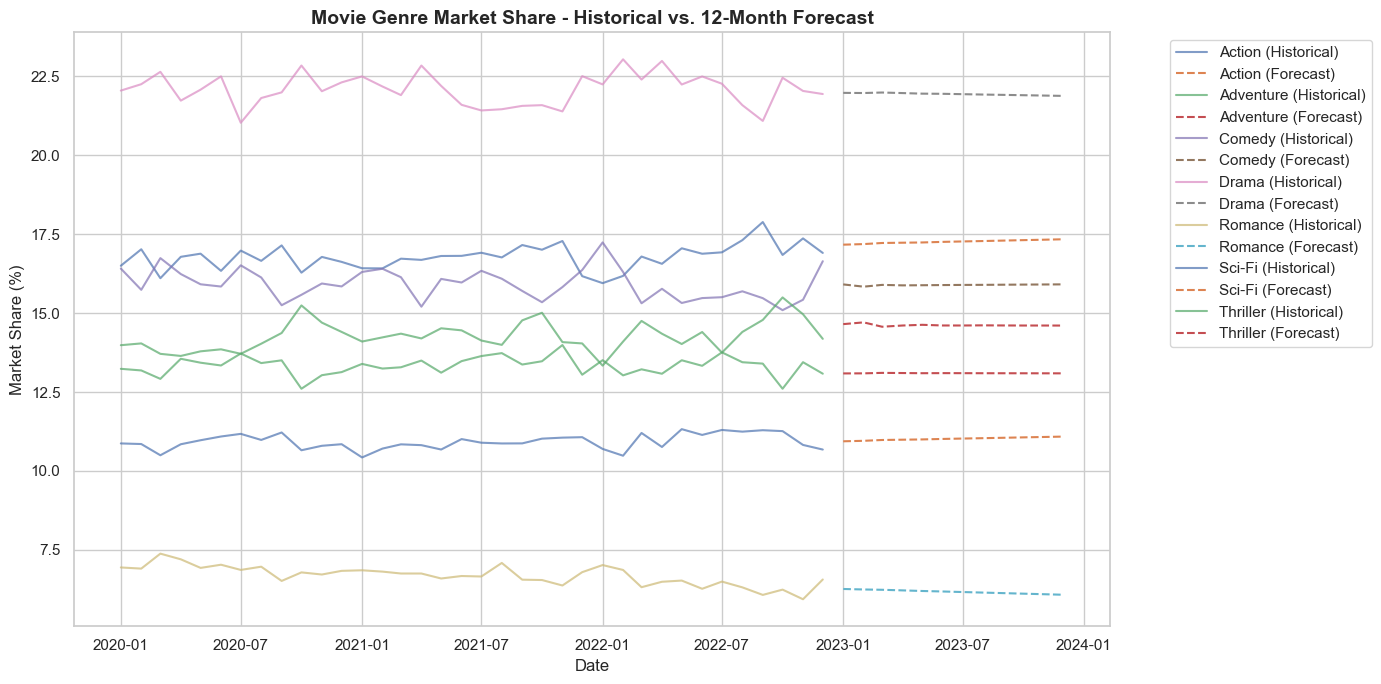

In [10]:
# Cell: Generate & Plot Forecasts and Historical Trends
plt.figure(figsize=(14, 7))

for g in GENRES[:7]: # Plotting a subset of genres for clarity (or loop through all of GENRES)
    # Plot historical data
    plt.plot(df.index[-36:], df[g].iloc[-36:], label=f"{g} (Historical)", alpha=0.7)
    # Plot normalized forecasts
    plt.plot(future_norm.index, future_norm[g], label=f"{g} (Forecast)", linestyle="--")

plt.title("Movie Genre Market Share - Historical vs. 12-Month Forecast", fontsize=14, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Market Share (%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

# Save figure
plt.savefig(D["figures"] / "genre_forecast_plot.png", dpi=300, bbox_inches="tight")
plt.show()